In [ ]:
pip install pandas

In [ ]:
pip install wget

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=44018bc2965815e1e27fe26b7fc3f25ff70a5590a5f03fd3e6eeb1530a2a26f7
  Stored in directory: /root/.cache/pip/wheels/40/b3/0f/a40dbd1c6861731779f62cc4babcb234387e11d697df70ee97
Successfully built wget


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Đọc file CSV (dùng dấu | để tách)
df = pd.read_csv('/content/drive/MyDrive/Data/car.csv', delimiter='|', on_bad_lines='skip')
print("DataFrame ban đầu:")
print(df)
print(df.info())

Mounted at /content/drive
DataFrame ban đầu:
       car_model         km             imp_exp       km_1  \
0      acura-mdx       0 Km           Nhập khẩu       0 Km   
1      acura-mdx       0 Km           Nhập khẩu       0 Km   
2      acura-mdx       0 Km           Nhập khẩu       0 Km   
3      acura-mdx       0 Km           Nhập khẩu       0 Km   
4      acura-mdx   9,600 Km           Nhập khẩu   9,600 Km   
...          ...        ...                 ...        ...   
39416  hang_khac       0 Km           Nhập khẩu       0 Km   
39417  hang_khac       0 Km  Lắp ráp trong nước       0 Km   
39418  hang_khac  25,000 Km  Lắp ráp trong nước  25,000 Km   
39419  hang_khac       0 Km  Lắp ráp trong nước       0 Km   
39420  hang_khac       0 Km  Lắp ráp trong nước       0 Km   

                imp_exp_1     car_type out_color   in_color door_num seat_num  \
0               Nhập khẩu          SUV       Đen        Đen    5 cửa    7 chỗ   
1               Nhập khẩu          SUV       Bạc

In [ ]:
# Tách dữ liệu trong cột đầu tiên dựa theo dấu "|"
split_columns = df.iloc[:, 0].str.split('|', expand=True)

In [ ]:
print(df.head())

   car_model        km    imp_exp      km_1  imp_exp_1 car_type out_color  \
0  acura-mdx      0 Km  Nhập khẩu      0 Km  Nhập khẩu      SUV       Đen   
1  acura-mdx      0 Km  Nhập khẩu      0 Km  Nhập khẩu      SUV       Bạc   
2  acura-mdx      0 Km  Nhập khẩu      0 Km  Nhập khẩu      SUV       Bạc   
3  acura-mdx      0 Km  Nhập khẩu      0 Km  Nhập khẩu      SUV       Đen   
4  acura-mdx  9,600 Km  Nhập khẩu  9,600 Km  Nhập khẩu      SUV     Trắng   

    in_color door_num seat_num new_old car_year                    title  \
0        Đen    5 cửa    7 chỗ   Xe cũ     2007  Acura MDX SH-AWD - 2007   
1        Đen    5 cửa    7 chỗ   Xe cũ     2007  Acura MDX SH-AWD - 2007   
2  Nhiều màu    5 cửa    7 chỗ   Xe cũ     2006  Acura MDX SH-AWD - 2006   
3        Kem    5 cửa    7 chỗ  Xe mới     2016    Acura MDX 3.5L - 2016   
4        Cát    5 cửa    7 chỗ   Xe cũ     2015    Acura MDX 3.5L - 2015   

            price    area                      poster_name  \
0       630 Triệu 

In [ ]:

df.columns = [
    'car_model', 'km', 'imp_exp', 'km_1', 'imp_exp_1', 'car_type',
    'out_color', 'in_color', 'door_num', 'seat_num', 'new_old',
    'car_year', 'title', 'price', 'area', 'poster_name',
    'poster_add', 'poster_tel'
]
print(df)

       car_model         km             imp_exp       km_1  \
0      acura-mdx       0 Km           Nhập khẩu       0 Km   
1      acura-mdx       0 Km           Nhập khẩu       0 Km   
2      acura-mdx       0 Km           Nhập khẩu       0 Km   
3      acura-mdx       0 Km           Nhập khẩu       0 Km   
4      acura-mdx   9,600 Km           Nhập khẩu   9,600 Km   
...          ...        ...                 ...        ...   
39416  hang_khac       0 Km           Nhập khẩu       0 Km   
39417  hang_khac       0 Km  Lắp ráp trong nước       0 Km   
39418  hang_khac  25,000 Km  Lắp ráp trong nước  25,000 Km   
39419  hang_khac       0 Km  Lắp ráp trong nước       0 Km   
39420  hang_khac       0 Km  Lắp ráp trong nước       0 Km   

                imp_exp_1     car_type out_color   in_color door_num seat_num  \
0               Nhập khẩu          SUV       Đen        Đen    5 cửa    7 chỗ   
1               Nhập khẩu          SUV       Bạc        Đen    5 cửa    7 chỗ   
2           

In [ ]:
# Giữ lại cột quan trọng
df = df[[
    'car_model', 'km', 'imp_exp', 'car_type', 'out_color',
    'in_color', 'door_num', 'seat_num', 'new_old', 'car_year',
    'title', 'price', 'area', 'poster_name', 'poster_add', 'poster_tel'
]]
print(df.head)

<bound method NDFrame.head of        car_model         km             imp_exp     car_type out_color  \
0      acura-mdx       0 Km           Nhập khẩu          SUV       Đen   
1      acura-mdx       0 Km           Nhập khẩu          SUV       Bạc   
2      acura-mdx       0 Km           Nhập khẩu          SUV       Bạc   
3      acura-mdx       0 Km           Nhập khẩu          SUV       Đen   
4      acura-mdx   9,600 Km           Nhập khẩu          SUV     Trắng   
...          ...        ...                 ...          ...       ...   
39416  hang_khac       0 Km           Nhập khẩu        Truck     Trắng   
39417  hang_khac       0 Km  Lắp ráp trong nước        Truck      Xanh   
39418  hang_khac  25,000 Km  Lắp ráp trong nước  Van/Minivan       Đen   
39419  hang_khac       0 Km  Lắp ráp trong nước        Truck      Xanh   
39420  hang_khac       0 Km  Lắp ráp trong nước        Truck      Xanh   

        in_color door_num seat_num new_old car_year                    title  \
0

In [ ]:
# Bước 1: Chuẩn hóa 'km'
df['km'] = df['km'].str.replace(' Km', '').str.replace(',', '')
df['km'] = pd.to_numeric(df['km'], errors='coerce')

In [ ]:
# Bước 2: Chuẩn hóa 'price'
def convert_price(p):
    try:
        p = p.lower().replace("triệu", "").replace(" ", "")
        if "tỷ" in p:
            ty, *trieu = p.split("tỷ")
            ty = float(ty)
            trieu = float(trieu[0]) if trieu and trieu[0] else 0
            return ty * 1000 + trieu
        else:
            return float(p)
    except:
        return np.nan

df['price'] = df['price'].apply(convert_price)

In [ ]:
# Bước 3: Chuẩn hóa 'new_old'
df['new_old'] = df['new_old'].map({'Xe cũ': 0, 'Xe mới': 1})

In [ ]:
df.head(10)

,car_model,km,imp_exp,car_type,out_color,in_color,door_num,seat_num,new_old,car_year,title,price,area,poster_name,poster_add,poster_tel
0,acura-mdx,0,Nhập khẩu,SUV,Đen,Đen,5 cửa,7 chỗ,0,2007,Acura MDX SH-AWD - 2007,630.0,TP HCM,Liên hệ: Salon ô tô Thịnh Lợi,"Số 56+58+60 (C3/1 cũ) Phạm Hùng, Bình Chánh TP...",ĐT: 0961 258 258 - 0943 331 999
1,acura-mdx,0,Nhập khẩu,SUV,Bạc,Đen,5 cửa,7 chỗ,0,2007,Acura MDX SH-AWD - 2007,580.0,Hà Nội,Liên hệ: Ngô Quốc Huy,Nguyễn khánh toán Hà Nội,ĐT: 0903 245 739
2,acura-mdx,0,Nhập khẩu,SUV,Bạc,Nhiều màu,5 cửa,7 chỗ,0,2006,Acura MDX SH-AWD - 2006,465.0,TP HCM,Liên hệ: Salon Auto Toàn Phát,"C1/25 Phạm Hùng Chánh Hưng, Bình Chánh TP HCM",ĐT: 0903 951 109 - 0938 595 373
3,acura-mdx,0,Nhập khẩu,SUV,Đen,Kem,5 cửa,7 chỗ,1,2016,Acura MDX 3.5L - 2016,4665.0,TP HCM,Liên hệ: Ôtô Ngọc Danh,"C3/02 Phạm Hùng, Quận 8 TP HCM",ĐT: 0919 726 666
4,acura-mdx,9600,Nhập khẩu,SUV,Trắng,Cát,5 cửa,7 chỗ,0,2015,Acura MDX 3.5L - 2015,3400.0,TP HCM,Liên hệ: Siêu Thị Ô Tô An Sương,"Nguyễn Ảnh Thủ, Bà Điểm, Hóc Môn TP HCM",ĐT: 0789 455 699 - 0993 777 977
5,acura-mdx,9700,Nhập khẩu,SUV,Trắng,Kem,5 cửa,7 chỗ,0,2015,Acura MDX 3.5L - 2015,3450.0,TP HCM,Liên hệ: Siêu Thị Ô Tô An Sương,"Nguyễn Ảnh Thủ, Bà Điểm, Hóc Môn TP HCM",ĐT: 0789 455 699 - 0993 777 977
6,acura-mdx,86000,Nhập khẩu,SUV,Đen,Đen,5 cửa,7 chỗ,0,2008,Acura MDX SH-AWD - 2008,620.0,Bình Dương,Liên hệ: Phạm Trung Dũng,Bình chuẩn Thuận An Bình Dương Bình Dương,ĐT: 0826 858 585 - 0362 727 272
7,acura-mdx,0,Nhập khẩu,SUV,Xanh,Nâu,5 cửa,7 chỗ,0,2004,Acura MDX 3.5L - 2004,290.0,Hải Dương,Liên hệ: dung,hai duong Hải Dương,ĐT: 0984 396 928
8,acura-mdx,80000,Nhập khẩu,SUV,Đen,Đen,5 cửa,7 chỗ,0,2007,Acura MDX SH-AWD - 2007,555.0,Hà Nội,Liên hệ: Auto Car Center,Số 9 Nguyễn Văn Cừ - Long Biên Hà Nội,ĐT: 0976 860 594
9,acura-mdx,150000,Nhập khẩu,SUV,Xám,Đen,5 cửa,7 chỗ,0,2008,Acura MDX SH-AWD - 2008,639.0,Hà Nội,Liên hệ: Dao van Thinh,Ngõ 100 hoàng quốc việt Hà Nội,ĐT: 0903 210 090


In [ ]:
# Lấy các cột cần thiết để phân cụm
data = df[['km', 'price', 'new_old']]

In [ ]:
# Chia tập dữ liệu thành train (80%) và test (20%)
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)

In [ ]:
# Số dòng của từng tập
train_count = len(train_data)
test_count = len(test_data)

train_data.head()

,km,price,new_old
936,97000,130.0,0
24459,9000,3799.0,0
673,0,780.0,0
26642,0,635.0,1
11206,0,334.0,0


In [ ]:
# b.Chuẩn hóa
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_data)

In [ ]:
# in ra 5 dòng đầu sau khi chuẩn hóa Standard
train_scaled[:5]

array([[-0.01465678, -0.41630378, -0.64928044],
       [-0.01626529,  1.49834488, -0.64928044],
       [-0.0164298 , -0.07710464, -0.64928044],
       [-0.0164298 , -0.15277214,  1.54016652],
       [-0.0164298 , -0.30984743, -0.64928044]])

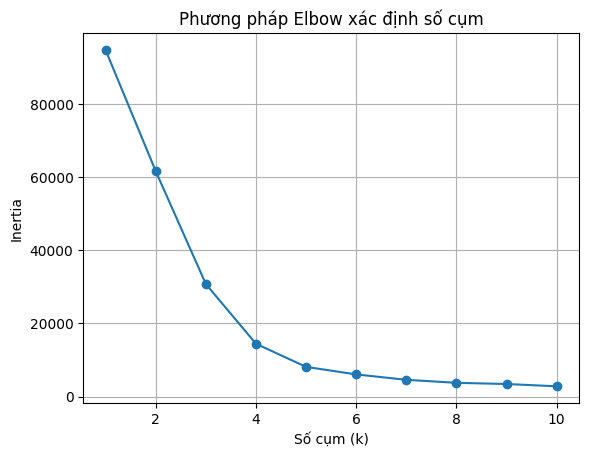

In [ ]:
# Elbow method
inertias = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(train_scaled)
    inertias.append(kmeans.inertia_)
plt.plot(k_values, inertias, marker='o')
plt.title('Phương pháp Elbow xác định số cụm')
plt.xlabel('Số cụm (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [ ]:
# Hiển thị các cột km, price, new_old
df[['km', 'price', 'new_old']].head(10)

,km,price,new_old
0,0,630.0,0
1,0,580.0,0
2,0,465.0,0
3,0,4665.0,1
4,9600,3400.0,0
5,9700,3450.0,0
6,86000,620.0,0
7,0,290.0,0
8,80000,555.0,0
9,150000,639.0,0


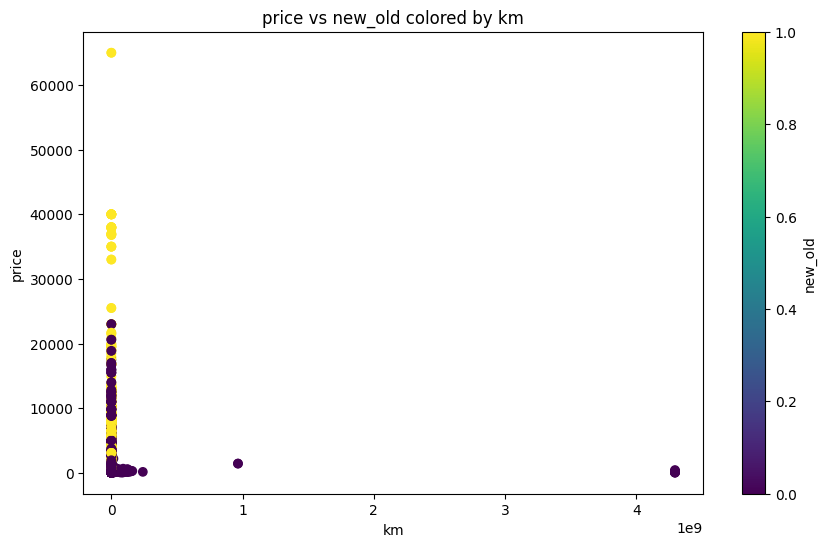

In [ ]:
# Hiển thị dữ liệu theo số km (km)
import matplotlib.pyplot as plt
# Hiển thị dữ liệu số km (km), giá (price), cũ_mới (new_old)
plt.figure(figsize=(10, 6))
plt.scatter(df['km'], df['price'], c=df['new_old'], cmap='viridis')
plt.title('price vs new_old colored by km')
plt.xlabel('km')
plt.ylabel('price')
plt.colorbar(label='new_old')
plt.show()

1. Phân bố xe mới (new_old = 1)
Chủ yếu tập trung ở vùng km thấp (bên trái) và price cao (trên cao).
Điều này phù hợp với thực tế: xe mới thường chưa đi nhiều và có giá cao hơn.

2. Phân bố xe cũ (new_old = 0):
Phân bố rộng hơn, trải từ km thấp đến cao và giá từ thấp đến trung bình.
Một số xe cũ vẫn có km thấp, nhưng đa số tập trung ở: km cao, price thấp

3. Xu hướng tổng thể:
Có một xu hướng ngược chiều giữa km và price:
⇒ Khi km tăng thì price giảm (tức là xe đi nhiều thì mất giá).

Điều này phù hợp với giả thuyết ban đầu:
"Xe cũ đi nhiều thì giá thấp"
"Xe mới đi ít thì giá cao"

In [ ]:
from sklearn.preprocessing import StandardScaler
# Tiền xử lý dữ liệu - Chuẩn hóa (Standardication)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[['km', 'price', 'new_old']])

# Kiểm tra số lượng bản ghi sau khi xử lý
print(f"Số lượng bản ghi sau khi xử lý: {df_scaled.shape[0]} ")

Số lượng bản ghi sau khi xử lý: 39421 


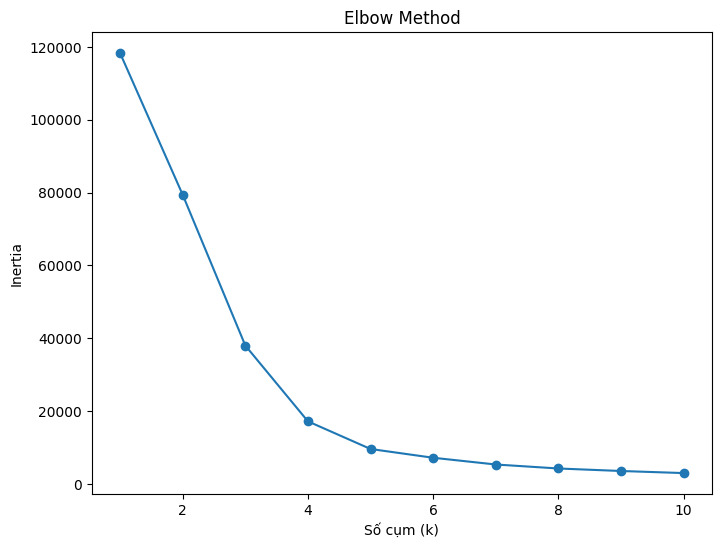

In [ ]:
# Tính số cụm bằng Elbow Method
from sklearn.cluster import KMeans

# Sử dụng Elbow Method để tính số cụm
inertias = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

# Vẽ đồ thị Elbow Method
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Số cụm (k)')
plt.ylabel('Inertia')
plt.show()

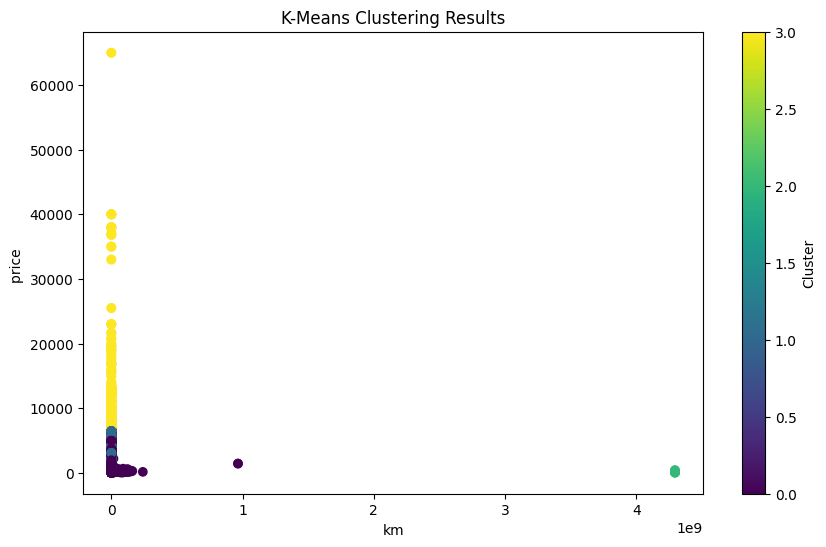

In [ ]:
# Dùng số cụm tính được để hiển thị lại dữ liệu
# Chọn số cụm là 4 từ Elbow Method
kmeans = KMeans(n_clusters=4, random_state=42)
df['Cluster'] = kmeans.fit_predict(df_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(df['km'],df['price'],c=df['Cluster'],cmap='viridis')
plt.title('K-Means Clustering Results')
plt.xlabel('km')
plt.ylabel('price ')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
# Dùng K-means gôm cụm dữ liệu test (Hold-out)
from sklearn.model_selection import train_test_split

# Chia dữ liệu thành train và test (80-20)
X_train, X_test = train_test_split(df_scaled, test_size=0.2, random_state=42)

# Huấn luyện mô hình Kmeans với dữ liệu train
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X_train)

# Dự đoán trên tập test
y_pred = kmeans.predict(X_test)

In [ ]:
# Hiển thị giá trị Centers tính được nhờ K-means
# Hiển thị các trung tâm cụm (centers)
centers = kmeans.cluster_centers_
print("Các trung tâm cụm (centers):")
print(centers)

Các trung tâm cụm (centers):
[[-1.82304541e-02  6.94160366e-02  1.53738953e+00]
 [-1.34690966e-02 -1.63574420e-01 -6.50453241e-01]
 [ 6.57161101e+01 -4.04799707e-01 -6.50453241e-01]
 [-1.81870948e-02  5.93304390e+00  1.10069436e+00]]


In [ ]:
# Sử dụng Sihouette để đánh giá chất lượng phân cụm
from sklearn.metrics import silhouette_score

# Tính Silhouette Score
sil_score = silhouette_score(df_scaled, df['Cluster'])
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.8494268979407936


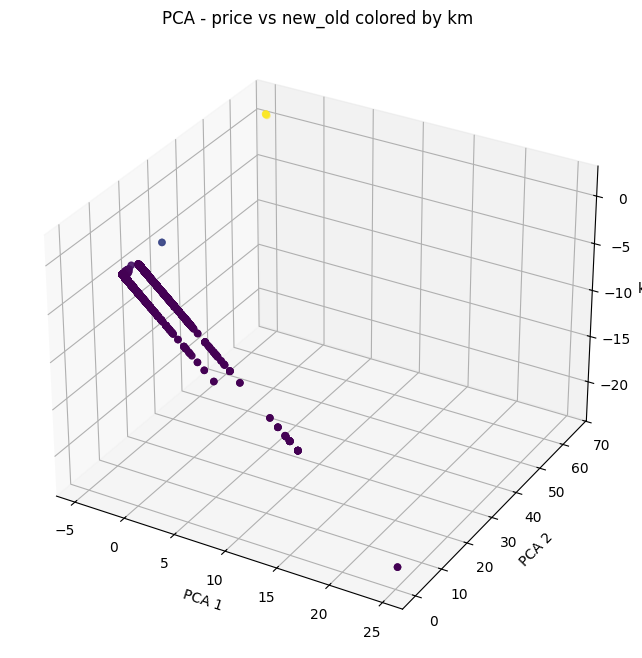

In [ ]:
# Dữ liệu có nhiều hơn 2 thuộc tính, trực quan hóa các cụm trong không gian 3D. Sử dụng PCA để giảm chiều dữ liệu và vẽ 3D
from sklearn.decomposition import PCA
# Giảm chiều vẽ 3D để trực quan hóa
pca = PCA(n_components=3)
pca_result = pca.fit_transform(df_scaled)

# Vẽ đồ thị 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pca_result[:, 0], pca_result[:, 1], pca_result[:, 2], c=df['km'], cmap='viridis')
ax.set_title('PCA - price vs new_old colored by km')
ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_zlabel('km')
plt.show()

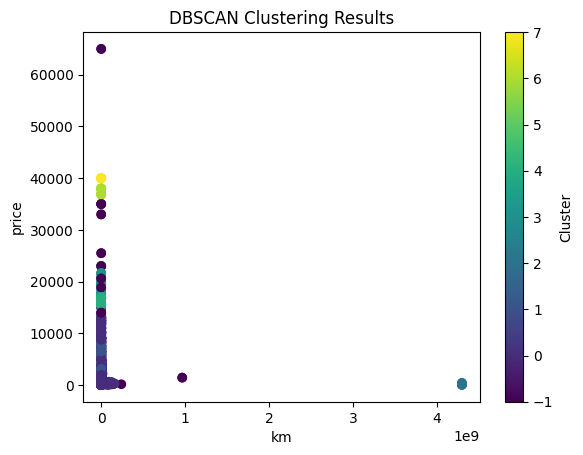

In [ ]:
# So sánh với DBSCAN
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)
cluster_dbscan = dbscan.fit_predict(df_scaled)

plt.scatter(df['km'], df['price'], c=cluster_dbscan, cmap='viridis')
plt.title('DBSCAN Clustering Results')
plt.xlabel('km')
plt.ylabel('price')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
# Sử dụng Kfold cross-validation với Silhouette Score
from sklearn.model_selection import KFold
from sklearn.metrics import silhouette_score
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

silhouette_scores = []

for train_index, test_index in kf.split(df_scaled):
  # Chia dữ liệu thành tập train và test
    X_train, X_test = df_scaled[train_index], df_scaled[test_index]

    # Huấn luyện KMeans
    kmeans = KMeans(n_clusters=4, random_state=42)
    kmeans.fit(X_train)

    # Dự đoán các cụm cho dữ liệu test
    cluster_labels = kmeans.predict(X_test)

    # Tính Silhouette Score
    silhouette_avg = silhouette_score(X_test, cluster_labels)
    silhouette_scores.append(silhouette_avg)

    print(f"Average Silhouette Score from CrossValidation: {np.mean(silhouette_scores)}")


Average Silhouette Score from CrossValidation: 0.852788793138942
Average Silhouette Score from CrossValidation: 0.8496094752177367
Average Silhouette Score from CrossValidation: 0.8500291322088088
Average Silhouette Score from CrossValidation: 0.8496216612471637
Average Silhouette Score from CrossValidation: 0.8493576987886888
